## Computational Model : oscillations and avalanches

In [ ]:
# Run from the repository folder (or Statistical Analysis).
# Put the downloaded datasets in data/, or set PLOSCB_DATA_DIR.
from pathlib import Path
import os
import sys

REPO_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "Modules").is_dir())
DATA_DIR = Path(os.environ.get("PLOSCB_DATA_DIR", str(REPO_DIR / "data"))).expanduser().resolve()
FIGURES_DIR = REPO_DIR / "figs"
sys.path.insert(0, str(REPO_DIR / "Modules"))

import numpy as np
import matplotlib.pyplot as plt
import numpy as np
import os

# Stable rat indices for the four files in Zenodo record 23187126.
DATA_FILES = tuple(str(DATA_DIR / name) for name in (
    "Piezo_02_220117_115929.mat",
    "Piezo_220131_114858.mat",
    "Piezo_220210_110252.mat",
    "Piezo_220211_114822.mat",
))

def select_rat():
    for index, filename in enumerate(DATA_FILES):
        print(f"{index}: {Path(filename).name}")
    while True:
        try:
            rat = int(input("Select rat (0, 1, 2, 3): "))
        except ValueError:
            print("Enter an integer from 0 to 3.")
            continue
        if rat not in range(4):
            print("Enter an integer from 0 to 3.")
            continue
        filename = DATA_FILES[rat]
        if not Path(filename).is_file():
            raise FileNotFoundError(
                f"Dataset file missing: {filename}. Download the four Zenodo files "
                "into DATA_DIR (data/ by default, or set PLOSCB_DATA_DIR).")
        print(f"Selected rat {rat}: {Path(filename).name}")
        return rat, filename



In [3]:
%load_ext autoreload
%autoreload 2

In [ ]:
# Use the dataset folder configured above, regardless of its storage device.
os.chdir(DATA_DIR)
label = DATA_DIR.name  # Dataset identifier used in output filenames.


In [5]:
import sys
import warnings
warnings.filterwarnings("ignore")

In [ ]:
path =str(REPO_DIR)
path_figures = str(FIGURES_DIR)

In [ ]:
sys.path.append(str(REPO_DIR / "Modules"))
from avalanches_functions import *
from functions import * 
from plotting_functions import *
import matplotlib
matplotlib.rc('font', **{'family':'serif', 'serif': ['Computer Modern']})
matplotlib.rc('text', usetex=True)

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['font.size'] = 25

In [ ]:
rat, selected_file = select_rat()
label = Path(selected_file).stem

import os
import numpy as np
import scipy.signal as ss
import mat73

file = DATA_FILES[rat]
data_dict = mat73.loadmat(file)
data = data_dict['amplifier_data']
stim = data_dict['adc_data'][0]
indexes = (np.where(stim> 1.5)[0])[np.where(np.diff(np.where(stim> 1.5)[0])>1)]
indexes = np.array(indexes.tolist() + [int(indexes[-1] + np.diff(indexes)[-1])]) - 125
fs = 25000


In [ ]:
len(indexes);


In [ ]:
import os
import numpy as np
import scipy.signal as ss
import scipy.signal as ss
fs = 25000
nTrials = len(indexes) -2
nchan = 30
import scipy.signal as ss
##spikes

fs = 25000
nyq = 0.5*fs
#T =10
T =int(input('insert T'))

low = 300/nyq
high = 3000/nyq
b,a = ss.butter(2,[low,high], "bandpass")
spikes = ss.filtfilt(b,a,data,axis = 1, padlen=150)
spikes = (spikes - np.mean(spikes,0)) # substracting mean population trend (artifact removal)

spikesTrials = []
spikes = (spikes[:nchan])
for r in range(1,nTrials+1):
    spikesTrials.append(spikes[:,indexes[r]-int(fs):indexes[r]+int(fs*T)])
spikesTrials = np.array(spikesTrials)


In [59]:
nch = spikesTrials.shape[1]
num = spikesTrials.shape[0]
binspikes =  np.zeros((num,nch,spikesTrials.shape[2]), dtype = int)
soglia = 4
for r in range(num):
    for ch in range(nch):
        binspikes[r,ch,:] = findpeaks(spikesTrials[r,ch,:],Thres(soglia,spikesTrials[r,ch,:]),"neg", dist=10)


In [61]:
def compute_fr_v(data, mean_interspike_time, coef):
    ev = data
    #ev = np.sum(data, axis=1).astype(int)
    T = int(mean_interspike_time * coef)

    cumsum = np.cumsum(np.insert(ev, 0, 0))
    density = (cumsum[T:] - cumsum[:-T]) / T

    # padding finale per mantenere stessa lunghezza
    density = np.concatenate([density, np.zeros(T-1)])

    return density
total_f = np.zeros(binspikes.shape)

for g in range(nTrials):
    for n in range(nch):
        f= compute_fr_v(binspikes[g,n,:], 500,3)
        total_f[g,n] = f

In [ ]:
trial = 1


In [ ]:
trial = 12


In [ ]:
trial = 12


In [ ]:
#from numba import njit
plt.rcParams['text.usetex'] =True
plt.rcParams['font.family'] = 'serif',
plt.rcParams['font.serif'] =  'Computer Modern'

In [66]:
plt.rcParams['font.size'] = 25

In [67]:
from scipy.special import erf

def WilsonCowan(t_final,dt,x_0,proc):

    def Acti(V,theta, rho, Tx):
        return (1 + erf((V -(theta - rho))/Tx))/2
    
    ec = 42
    ic = 12
    tce = 12
    tci = 10
    taue = 5
    taui = 15
    
    wee = 1
    wei = 1
    
    wie = 2
    wii = 1.5
    
    wte = 3.9
    wti = 1.5### original 6
    gamma_e = 5
    gamma_i = 15
    
    er = 2.2##original 7.4
    ir = 4.1
    
    Te = 12.03
    Ti = 11.62
    rho = -60
    theta = -45
    
    
    S0 =np.random.random(2)*x_0
    
    T = t_final
    N = int(T/dt)
  
    S = np.zeros((2,N))
    P = np.zeros(N)
    S[:,0] = S0
    for r in range(N-1):
        P[r] = gamma_e*(1-er*Acti(S[0,r],theta,rho,Te))*Acti(wee*ec*S[0,r]+ wte*tce*(proc[r])-wie*ic*S[1,r],theta,rho,Te)
        S[0,r+1] = S[0,r] +(-S[0,r] + P[r])*dt/taue
        S[1,r+1] = S[1,r] +(-S[1,r] + gamma_i*(1-ir*Acti(S[1,r],theta,rho,Ti))*Acti(wei*ec*S[0,r]+ wti*tci*(proc[r])-wii*ic*S[1,r],theta,rho,Ti))*dt/taui
    P[-1] = gamma_e*(1-er*Acti(S[0,-1],theta,rho,Te))*Acti(wee*ec*S[0,-1]+ wte*tce*(proc[-1])-wie*ic*S[1,-1],theta,rho,Te)
    
    return S, P

In [68]:
#import sys
#sys.path.append(path_comp)

from avalanches_functions import *
from functions import *
from plotting_functions import *
from power import * 
from powerlaw_fit import *
from stats import *

In [69]:
#T

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
period = T
trial = 1
fir = total_f[:, 6:12, :]
fir = fir.transpose(0, 2, 1)
mean_ch = np.mean(fir[trial], 1) * 25
T = 1000 * (period + 1)
sample_rate = 25000
taue = 5
dt = 0.04
N = int(T / dt)
times = np.arange(0, T, 0.04)
times = times * 0.001
sigma_samples = 100
smoothed = gaussian_filter1d(mean_ch, sigma=sigma_samples)
psth = (smoothed - 0.0) / (np.max(smoothed) - 0.0) * 0.3
proc = np.zeros(N)
for g in range(N - 1):
    proc[g + 1] = proc[g] + (-proc[g] * dt + psth[g] * dt) / taue
S = WilsonCowan(T, dt, 2, proc)
ii = 35
proc_rest = proc
S_rest = S[1]

def detect_avalanches(firing_rate, threshold):
    """
    Calcola le valanghe in una traccia di firing rate.
    Restituisce anche gli intervalli start-end di ciascuna valanga.
    """
    above_thresh = firing_rate > threshold
    avalanche_sizes = []
    avalanche_intervals = []
    avalanche_dur = []
    in_avalanche = False
    start_idx = 0
    o = 0
    for (i, active) in enumerate(above_thresh):
        if active and (not in_avalanche):
            in_avalanche = True
            start_idx = i
        elif not active and in_avalanche:
            in_avalanche = False
            end_idx = i
            area = np.sum(firing_rate[start_idx:end_idx] - threshold)
            avalanche_sizes.append(area)
            avalanche_intervals.append((start_idx, end_idx))
            avalanche_dur.append(end_idx - start_idx)
    if in_avalanche:
        area = np.sum(firing_rate[start_idx:] - threshold)
        avalanche_sizes.append(area)
        avalanche_intervals.append((start_idx, len(firing_rate)))
        avalanche_dur.append(len(firing_rate) - start_idx)
    start = np.where(np.diff(above_thresh.astype(int)) > 0)
    end = np.where(np.diff(above_thresh.astype(int)) < 0)
    return (avalanche_sizes, avalanche_intervals, avalanche_dur, start, end)
threshold = 0.3
(avalanches, intervals, dur, s, e) = detect_avalanches(S_rest, threshold)
T = 1000 * (period + 1)
sample_rate = 25000
taue = 5
dt = 0.04
N = int(T / dt)
times = np.arange(0, T, 0.04)
times = times * 0.001 - 1
for (start, end) in intervals:
    pass


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
trial = 1
fir = total_f[:, 6:12, :25000 * 11]
fir = fir.transpose(0, 2, 1)
mean_ch = np.mean(fir[trial], 1) * 25
T = 1000 * (period + 1)
sample_rate = 25000
taue = 5
dt = 0.04
N = int(T / dt)
times = np.arange(0, T, 0.04)
times = times * 0.001
sigma_samples = 100
smoothed = gaussian_filter1d(mean_ch, sigma=sigma_samples)
psth = (smoothed - 0.01) / (np.max(smoothed) - 0.01) * 0.3
psth = smoothed / np.max(smoothed) * 0.3
proc = np.zeros(N)
for g in range(N - 1):
    proc[g + 1] = proc[g] + (-proc[g] * dt + psth[g] * dt) / taue
S = WilsonCowan(T, dt, 2, proc)
ii = 35
proc_rest = proc
S_rest = S[1]

def detect_avalanches(firing_rate, threshold):
    """
    Calcola le valanghe in una traccia di firing rate.
    Restituisce anche gli intervalli start-end di ciascuna valanga.
    """
    above_thresh = firing_rate > threshold
    avalanche_sizes = []
    avalanche_intervals = []
    avalanche_dur = []
    in_avalanche = False
    start_idx = 0
    o = 0
    for (i, active) in enumerate(above_thresh):
        if active and (not in_avalanche):
            in_avalanche = True
            start_idx = i
        elif not active and in_avalanche:
            in_avalanche = False
            end_idx = i
            area = np.sum(firing_rate[start_idx:end_idx] - threshold)
            avalanche_sizes.append(area)
            avalanche_intervals.append((start_idx, end_idx))
            avalanche_dur.append(end_idx - start_idx)
    if in_avalanche:
        area = np.sum(firing_rate[start_idx:] - threshold)
        avalanche_sizes.append(area)
        avalanche_intervals.append((start_idx, len(firing_rate)))
        avalanche_dur.append(len(firing_rate) - start_idx)
    start = np.where(np.diff(above_thresh.astype(int)) > 0)
    end = np.where(np.diff(above_thresh.astype(int)) < 0)
    return (avalanche_sizes, avalanche_intervals, avalanche_dur, start, end)
threshold = 0.3
(avalanches, intervals, dur, s, e) = detect_avalanches(S_rest, threshold)
T = 1000 * (period + 1)
sample_rate = 25000
taue = 5
dt = 0.04
N = int(T / dt)
times = np.arange(0, T, 0.04)
times = times * 0.001 - 1
for (start, end) in intervals:
    pass


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
S_trial =[]
proc_trial =[]
for trial in range(num):
    
    fir = total_f[:,6:12,:25000*11]
    #rint(fir.shape)
    fir = fir.transpose(0,2,1)
    mean_ch = np.mean(fir[trial], 1)*25

    T = 1000*(period+1)
    sample_rate = 25000
    taue = 5
    dt = 0.04
    N = int(T/dt)
    times = np.arange(0,T,0.04)
    times = times*1e-3

    sigma_samples = 100 # ad esempio 5 campioni
    smoothed = gaussian_filter1d(mean_ch, sigma=sigma_samples)
    
    psth = (smoothed-0.)/(np.max(smoothed)-0.)*0.3#*25*7
    proc = np.zeros(N)
    
    for g in range(N-1):
        proc[g+1] = proc[g] +(-proc[g]*dt + psth[g]*dt)/taue
    
    S = WilsonCowan(T,dt,2,proc)
    ii = 35
    proc_rest = proc
    S_rest = S[1]
    Syn_drive =S[0][0]
    S_trial.append([S_rest,Syn_drive])
    proc_trial.append(proc_rest)

In [ ]:
S_trial = np.asarray(S_trial)
proc_trial = np.asarray(proc_trial)
T = 1000 * (period + 1)
trial = 1
dt = 0.04
N = int(T / dt)
times = np.arange(0, T, 0.04)
times = times * 0.001 - 1


In [81]:
def poisson_thinning_vectorized(F, dt, N_neurons):

    dt_sec = 0.04
    N_time = len(F)
    lambda_max = np.max(F)
    
    # 1. Genera inter-event times da Poisson con rate lambda_max
    # Stimiamo il numero massimo di candidate spikes: poisson(lambda_max * T)
    T_sec = N_time * dt_sec
    N_candidates = int(lambda_max * T_sec * 1.5)  # safety factor
    
    # per tutti i neuroni: generiamo candidate spike times uniformemente su [0, T]
    candidate_times = np.random.rand(N_neurons, N_candidates) * T_sec
    
    # mappiamo ciascun candidato al bin temporale più vicino
    candidate_bins = np.minimum((candidate_times / dt_sec).astype(int), N_time-1)
    
    # thinning: accetta spike con probabilità F(t)/lambda_max
    accept = np.random.rand(N_neurons, N_candidates) < (F[candidate_bins]/lambda_max)
    
    # inizializziamo spike train
    ev = np.zeros((N_neurons, N_time), dtype=float)
    
    # inseriamo gli spike accettati
    for n in range(N_neurons):
        ev[n, candidate_bins[n, accept[n]]] = 1.0
    
    return ev
S_trial = np.asarray(S_trial)
ev_trial = []
for vect in S_trial[:,0,:]:
    ev = poisson_thinning_vectorized(vect,0.04,30)
    ev_trial.append(ev)


In [ ]:
#del spikes, spikesTrials, data

In [ ]:
ev_trial = np.asarray(ev_trial)


In [84]:
concat = concatenat_spikes(ev_trial,3,period +1,num,fs = 25000)

In [ ]:
#ev = np.zeros((20,25000*11))
#N = ev.shape[1]
#dt = 0.04
#for g in range(ev.shape[0]):
    #spikes2 = np.zeros((N,))
    #rnumbers = np.random.random(N)
    #prob = S_rest*dt
    #spikes2[rnumbers<prob] = 1
    #ev[g,:] = spikes2


In [44]:
def poisson_thinning(F, T,N_neurons):
    # F = rate array in Hz, uniform dt
    dt = 0.04
    #T / len(F)
    dt_sec = dt
    lambda_max = np.max(F)
    spikes = []

    for n in range(N_neurons):
        t = 0.0
        neuron_spikes = []
        while t < T:  # convert ms -> s
            # inter-event time from max rate Poisson
            dt_event = np.random.exponential(1/lambda_max)
            t += dt_event
            # accept spike with thinning
            idx = int(t/dt_sec)
            if idx >= len(F):
                break
            if np.random.rand() < F[idx]/lambda_max:
                neuron_spikes.append(t)
        spikes.append(neuron_spikes)
    return spikes
import numpy as np


In [ ]:
#del pos, ev , spikes2

In [86]:
#start_rest,end_rest=2,10
restspikes =concat
#ev.T
#concatenat_spikes(binspikes[:,20:],start_rest,end_rest,nTrials, fs=25000)
#binspikes.shape,restspikes.shape
S_shape_ = np.zeros((restspikes.shape[0]))
for ch in range(restspikes.shape[1]):
    S_shape_ += restspikes[:,ch]

sizes, durations, S_shape, shape_mean, freq = avalanche_finder(S_shape_,1)

In [ ]:
avinterv(S_shape_), S_shape_.shape[0]/58/25000;


In [ ]:
#from plotting_functions import *
#from avalanches_functions import *

In [ ]:
def scaling_new(sizes, durations, avinterval,
                lim1 = 4, lim2 = 4,
                tau = "default", errtau = "default",
                alpha = "default", erralpha = "default",
                maxxminsizes = "default", maxxmindur = "default",
                xmaxsizes = "default", xmaxdur = "default",size_lim="default", dur_lim="default"):
            
    if maxxminsizes ==  "default":
        maxxminsizes = max(sizes)
    if xmaxsizes ==  "default":
        xmaxsizes = max(sizes)
    if maxxmindur ==  "default":
        maxxmindur = max(durations)
    if xmaxdur ==  "default":
        xmaxdur = max(durations)
    if size_lim ==  "default":
        size_lim = max(sizes)
    if dur_lim ==  "default":
        dur_lim = max(durations)
    
    if tau == "default" and errtau == "default":
        xmin,tau,errtau = return_param(sizes,maxxmin = maxxminsizes,xmax =xmaxsizes,lim = lim1)
        
    if alpha == "default" and erralpha == "default":
        xmin,alpha,erralpha = return_param(durations,maxxmin = maxxmindur,xmax =xmaxdur,lim = lim2)

    pred =  delta(alpha, erralpha, tau, errtau)[0]
    errpred = delta(alpha, erralpha,tau, errtau)[1]
    
    durations = np.array(durations)*avinterval
    xmin1 = min(sizes)
    xmin2 = min(durations)

    xmax1 = size_lim
    xmax2 = dur_lim

    prova = np.array([np.asarray(sizes), np.asarray(durations)])
    prova = prova.transpose()
    prova2 = [0 for i in range(len(prova))]
    
    for r in range(len(prova)):
        if prova[r][0] < xmin1 or prova[r][1] < xmin2 or prova[r][0] > xmax1 or prova[r][1] > xmax2:
            prova2[r] = False
        else:
            prova2[r] = True
  
    new = prova[prova2]
    a, b, c = sgivent(new[:,0],new[:,1])
    
    x = np.hstack((np.log10(a).reshape(-1,1), np.ones(len(a)).reshape(-1,1)))
    
    y = np.log10(b).reshape(-1,1)

    ols = sm.OLS(y,x)
    ols_result = ols.fit()
    fit = ols_result.params[0]
    errfit = ols_result.bse[0]
    inter =ols_result.params[1]    
    print('Prediction from crackling noise relation: delta = ',pred, '+-', errpred)
    print('Fit from of average size given duration points: delta = ',fit, '+-', errfit)
    
    x = np.arange(min(durations),max(durations))
    a, b, c = sgivent(prova[:,0],prova[:,1])
    
    return a, b, c, x, inter, pred, errpred, fit, errfit

In [91]:
s = [sizes]
d = [durations]
extrinsic_par = []
h = 0

temp = []
sizes = s[h]
durations = d[h]

xm = max(sizes) if h == 0 else max(sizes)


expo = False
centredbin, pdfnorm, x, px_fit, exp, errexp, xmin = LogScript_new(sizes,1,4, xm,'default', expo)
print(xmin)

temp.append([centredbin, pdfnorm, x, px_fit, exp, errexp, xmin])
xm2 = max(durations) if h == 0 else max(durations)

centredbin, pdfnorm, x, px_fit, exp, errexp, xmin = LogScript_new(durations,1,4,xm2,'default', expo)
temp.append([centredbin, pdfnorm, x, px_fit, exp, errexp, xmin])
a, b, c, x, inter, pred, errpred, fit, errfit = scaling_new(sizes,durations,1,4,4,
                                                            'default','default','default',
                                                            'default',xm,xm2,'default','default',100,100)
print(xmin)
temp.append([sizes, durations, a, b, c, x, inter, pred, errpred, fit, errfit])
extrinsic_par.append(temp)

In [98]:
max(sizes)

In [92]:
ev_trial = np.asarray(ev_trial)
import emd
aas =[]

from numpy import *
fs = 25000
#for r in range(15,22):
for s in range(binspikes.shape[0]):
    v = emd.sift.mask_sift(S_trial[s,1,25000*3:], mask_freqs= 35./fs, max_imfs=5, ) # Synaptic drive
    low = 3
    IP, IF, IA = emd.spectra.frequency_transform(v, fs, 'nht')
    phi = IP[:,low][:]
    coef = 1
    param = 500
    amp = compute_density(ev_trial[s,:,25000*3:].T,param,coef)
    
    p_bins = arange(0, 2*pi, 0.1)
    a_mean = zeros(size(p_bins)-1)
    p_mean = zeros(size(p_bins)-1)
    for k in range(size(p_bins)-1):     #For each phase bin,
        pL = p_bins[k]                  #... lower phase limit,
        pR = p_bins[k+1]                #... upper phase limit.
        indices=(phi>=pL) & (phi<pR)    #Find phases falling in bin,
        a_mean[k] = mean(amp[indices])  #... compute mean amplitude,
        p_mean[k] = mean([pL, pR])      #... save center phase.
    aas.append(a_mean)    
  

In [ ]:
proc_trial = np.asarray(proc_trial)


In [ ]:
type(proc_trial)

In [95]:
S_trial = np.asarray(S_trial)

In [ ]:
# Dataset selection no longer uses a directory offset.

### Figura Avalanches

In [96]:
from functions import *
from plotting_functions import *

In [ ]:
trial = 20
ev = ev_trial[trial]
pos = [np.where(row > 0)[0] for row in ev]
t = np.arange(ev.shape[1]) / 25000
ticks = np.arange(0, 11, 1)


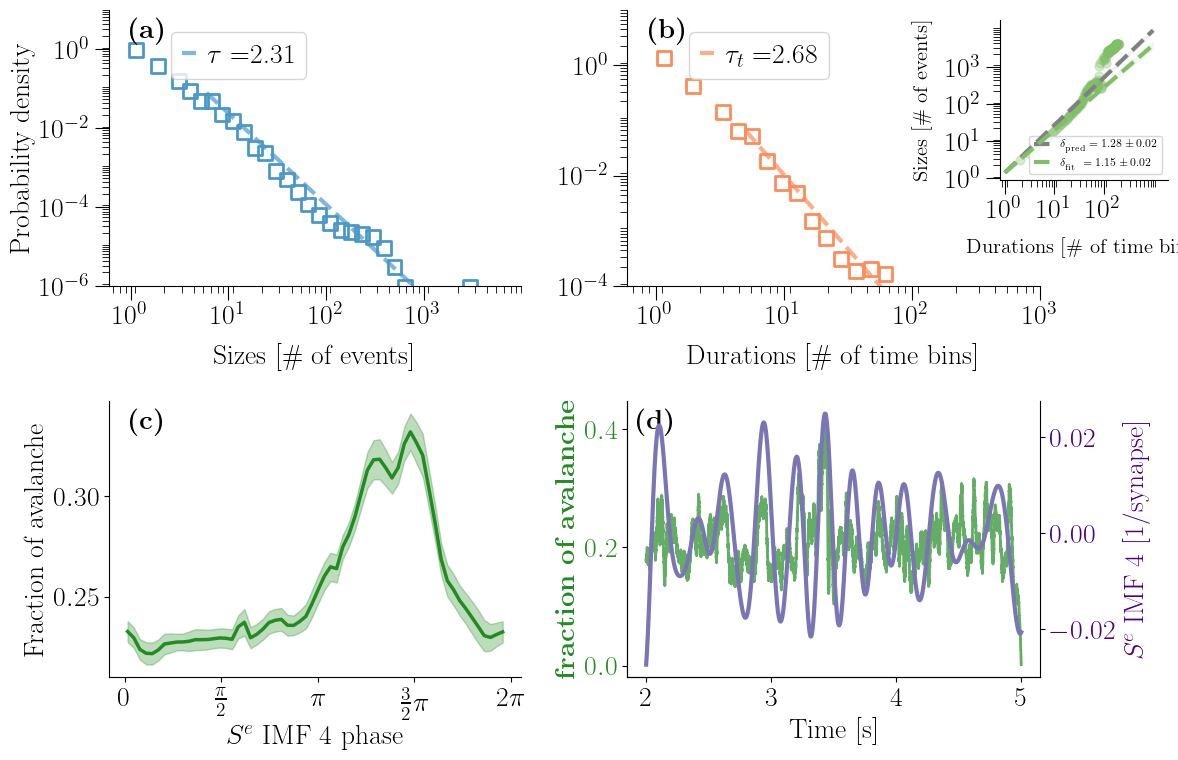

In [ ]:
# import emd
sample_rate = 25000

plt.rcParams['font.size'] = 20
plt.rcParams['axes.spines.top']= False
plt.rcParams['axes.spines.right']= False

if expo == True:
    prediz = False
    plot_fit = False
else:
    prediz = True
    plot_fit = True
from mpl_toolkits.axes_grid1 import make_axes_locatable

fig, ax = plt.subplots(2,2,figsize =(12,8))
left, bottom, width, height  = [0.85, 0.75, 0.14, 0.2]

ax3 = fig.add_axes([left, bottom, width, height])


color = ['blue', 'red']
#datasizes = [size]
for h in range(1):
    plot_av_statistics(ax[0,0], extrinsic_par[h][0][:-1], color = cm.get_cmap('Blues')(0.6),
                       xmin = extrinsic_par[h][0][-1], xmax = max(sizes), label = r"$\tau$ ="+f"{round(extrinsic_par[h][0][:-1][-2],2)}",
                       marker = 's', s = 100, lw = 2, lwline = 3, alphaline = 0.7,
                       plot_fit = plot_fit,expo = expo)
   
    
    ax[0,0].set_xlim(0.6,10000)
    ax[0,0].set_ylim(0.000001,10)
    ax[0,0].set_xticks(np.logspace(0,3,4))

    ax[0,0].set_xlabel(r'Sizes [\# of events]', labelpad = 10)
    
    plot_av_statistics(ax[0,1], extrinsic_par[h][1][:-1], color = cm.get_cmap('OrRd')(0.5),
                   xmin = extrinsic_par[h][1][-1], xmax = max(durations), label = r"$\tau_t$ ="+ f"{round(extrinsic_par[h][1][:-1][-2],2)}",
                   marker = 's', s = 100, lw = 2, lwline = 3, alphaline = 0.7,
                   plot_fit = plot_fit, expo= expo)
    
  
    ax[0,1].set_xlim(0.6,500)
    ax[0,1].set_ylim(0.0001,10)
    ax[0,1].set_xticks(np.logspace(0,3,4))

    ax[0,1].set_xlabel(r'Durations [\# of time bins]', labelpad = 10)
    
    xmax = 1000

    
    plot_crackling_noise(ax3, extrinsic_par[h][2], cpoints = 'forestgreen',
                         cpred = 'gray', cfit = cm.get_cmap('summer_r')(0.5),
                         xmin = 1, xmax = xmax, alphamarker = 0.3, s = 40, lwline = 3, prediz= prediz)
  
    ax3.legend(handletextpad=0.4, handlelength = 2, scatteryoffsets = [0.5],
              fontsize = 8, loc = 'lower right')

    ax3.set_xlim(0.8,2000)
    ax3.set_xticks([1,10,100])
    ax3.set_yticks([1,10,100,1000])
    
if not expo: 
    ax[0,0].legend(handletextpad=0.4, handlelength = 0.5, scatteryoffsets = [0.5],
                   fontsize = 20, loc = (0.15,0.75))
    ax[0,1].legend(handletextpad=0.4, handlelength = 0.5, scatteryoffsets = [0.5],
                   fontsize = 20, loc = (0.15,0.75))

ax[0,0].set_ylabel('Probability density',)
#ax[0].yaxis.set_label_coords(-0.2,-0.17)



for ax_ in [ax[0,0],ax[0,1],ax3]:
    locmin = matplotlib.ticker.LogLocator(base=10.0,subs=np.linspace(0,1,10),numticks=10)
    ax_.xaxis.set_minor_locator(locmin)
    ax_.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    locmin = matplotlib.ticker.LogLocator(base=10.0,subs=np.linspace(0,1,10),numticks=10)
    ax_.yaxis.set_minor_locator(locmin)
    ax_.yaxis.set_minor_formatter(matplotlib.ticker.NullFormatter())

    ax_.tick_params(length = 5, which = 'minor')
    ax_.tick_params(length = 10)

#from scipy import ndimage
mean_interspike_time = 3
coef = 5

aasmean = np.roll(np.mean(np.asarray(aas),0),35)
aas2 = np.roll(np.asarray(aas),35)

ax[1,0].fill_between(p_mean,aasmean - np.std(aas2,0)/np.sqrt(len(aas2)),aasmean+ np.std(aas2,0)/np.sqrt(len(aas)),color='forestgreen', alpha =.3)
ax[1,0].plot(p_mean, aasmean, color ='forestgreen', lw = 2.5)
ax[1,0].set_xlabel(r'$S^{e}$ IMF 4 phase')
ax[1,0].set_ylabel('Fraction of avalanche');


plt.rcParams['axes.spines.right']= True

t = np.arange(0,25000*(period-2),1)/25000 + 2
trial_ = 5

fs = 25000

v = emd.sift.mask_sift(S_trial[trial_,1,25000*3:], mask_freqs= 35./fs, max_imfs=5, )
amp = compute_density(ev_trial[trial_,:,25000*3:].T, param,1 )
ax[1,1].plot(t,amp, color = 'forestgreen', lw = 2,alpha = .7)

ax[1,1].set_ylabel(r'\textbf{fraction of avalanche} ', color='forestgreen',)  # we already handled the x-label with ax1

ax[1,1].set_xlabel('Time [s]')
ax[1,1].tick_params(axis='y', labelcolor='forestgreen',)

ax2 = ax[1,1].twinx() # instantiate a second Axes that shares the same x-axis
#ax[1,1].set_xlim(5,8)
color = 'indigo'
#_,_,IA_low=  emd.spectra.frequency_transform((v[:,3] + v[:,4]), sample_rate, 'nht')
ax2.tick_params(axis='y', labelcolor=color)
ax2.plot(t, (v[:,3] ), color = cm.get_cmap('Purples')(0.65), lw = 3,alpha = 1)
ax2.set_ylabel(r'$S^{e}$ IMF 4 [1/synapse]', color =color)



ax[1,0].set_xticks([0,np.pi/2,np.pi,3/2*np.pi, 2*np.pi])
ax[1,0].set_xticklabels(["0",r"$\frac{\pi}{2}$",r"$\pi$",r"$\frac{3}{2}\pi$", r"$2\pi$"])


ax[1,0].annotate('\\textbf{(c)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05, 0.9), textcoords='axes fraction')
ax[1,1].annotate('\\textbf{(d)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.02,0.9), textcoords='axes fraction')

ax[0,0].annotate('\\textbf{(a)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05, 0.9), textcoords='axes fraction')
ax[0,1].annotate('\\textbf{(b)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05,0.9), textcoords='axes fraction')

plt.tight_layout()
plt.savefig(path_figures+f"/Figura_5a_model_{rat}_{label}.jpg", dpi = 300, bbox_inches = 'tight')
plt.savefig(path_figures+f"/Figura_5a_model_{rat}_{label}.tif", dpi = 300, bbox_inches = 'tight')

In [ ]:
len(p_mean), len(p_bins),;


### Figura 5 a (oscillations)

In [ ]:
import emd
from scipy import signal
from mpl_toolkits.axes_grid1 import make_axes_locatable
final_rest = []

pspectrum = []
sample_rate = 25000
pspectrum =[]
for trial in range(fir.shape[0]):
    ii = 35

    x = S_trial[trial,1,25000*3:]
    imf2 = emd.sift.mask_sift(x, mask_freqs =ii/sample_rate)
    IP, IF, IA = emd.spectra.frequency_transform(imf2, sample_rate, 'nht')
    freq_range = (0, 45, 64)

    hht_f, spec = emd.spectra.hilberthuang(IF, IA, freq_range, scaling='density', sum_imfs=False)
    #hht_f, spec_nonlinear = emd.spectra.hilberthuang(IF_nonlinear, IA_nonlinear, freq_range, scaling='density', sum_imfs=False)

    final_rest.append(spec[:,:6])
    #for i in range[5,100,1000,2000,25000]:
    fss, p = signal.welch(x,fs = 25000,nperseg=20000)
    pspectrum.append(p)
    #plt.plot(fs,p)
final_rest = np.asarray(final_rest)


In [ ]:
len(fs), len(fs_2), len(S_trial[trial,1,25000*3:]), len(S_trial[trial,1,25000:25000*3]);


In [ ]:
import emd
from mpl_toolkits.axes_grid1 import make_axes_locatable
final = []
pspectrum_s=[]
for trial in range(fir.shape[0]):
    x = S_trial[trial,1,25000:25000*3]
    imf2 = emd.sift.mask_sift(x, mask_freqs =ii/sample_rate)
    IP, IF, IA = emd.spectra.frequency_transform(imf2, sample_rate, 'nht')
    freq_range = (0, 45, 64)
    hht_f, spec = emd.spectra.hilberthuang(IF, IA, freq_range, scaling='density', sum_imfs=False)
    #hht_f, spec_nonlinear = emd.spectra.hilberthuang(IF_nonlinear, IA_nonlinear, freq_range, scaling='density', sum_imfs=False)
    final.append(spec[:,:6])


    fss_2, p = signal.welch(x,fs = 25000, nperseg = 20000)
    pspectrum_s.append(p)

final = np.asarray(final)


In [117]:

#aa = []
aa1 = []

for tr in range(fir.shape[0]):
    x = S_trial[tr,1,25000*3:]
    t = np.arange(0,len(x),1)/sample_rate
    num = int(len(x)/sample_rate)
    ii = 35
    imf = emd.sift.mask_sift(x, max_imfs=9, mask_freqs= ii/sample_rate, ret_mask_freq=True)
    IP, IF, IA = emd.spectra.frequency_transform(imf[0], sample_rate, 'nht')
    ref1 = 3
    ref2 = 1
    #ref3 = 2

    #IP, IF, IA = emd.spectra.frequency_transform(imf[0], sample_rate, 'nht')
    ia_by_phase2, ia_by_phase_var2, phase_bins2 = emd.cycles.bin_by_phase(IP[:,ref1], IA[:, ref2], variance_metric ='std')
    phase_bins2 = phase_bins2[~np.isnan(ia_by_phase2)]
    ia_by_phase_var2 = ia_by_phase_var2[~np.isnan(ia_by_phase2)]
    ia_by_phase2 = ia_by_phase2[~np.isnan(ia_by_phase2)]
    #aa.append((ia_by_phase2-np.mean(ia_by_phase2))/np.std(ia_by_phase2))
    aa1.append(ia_by_phase2)

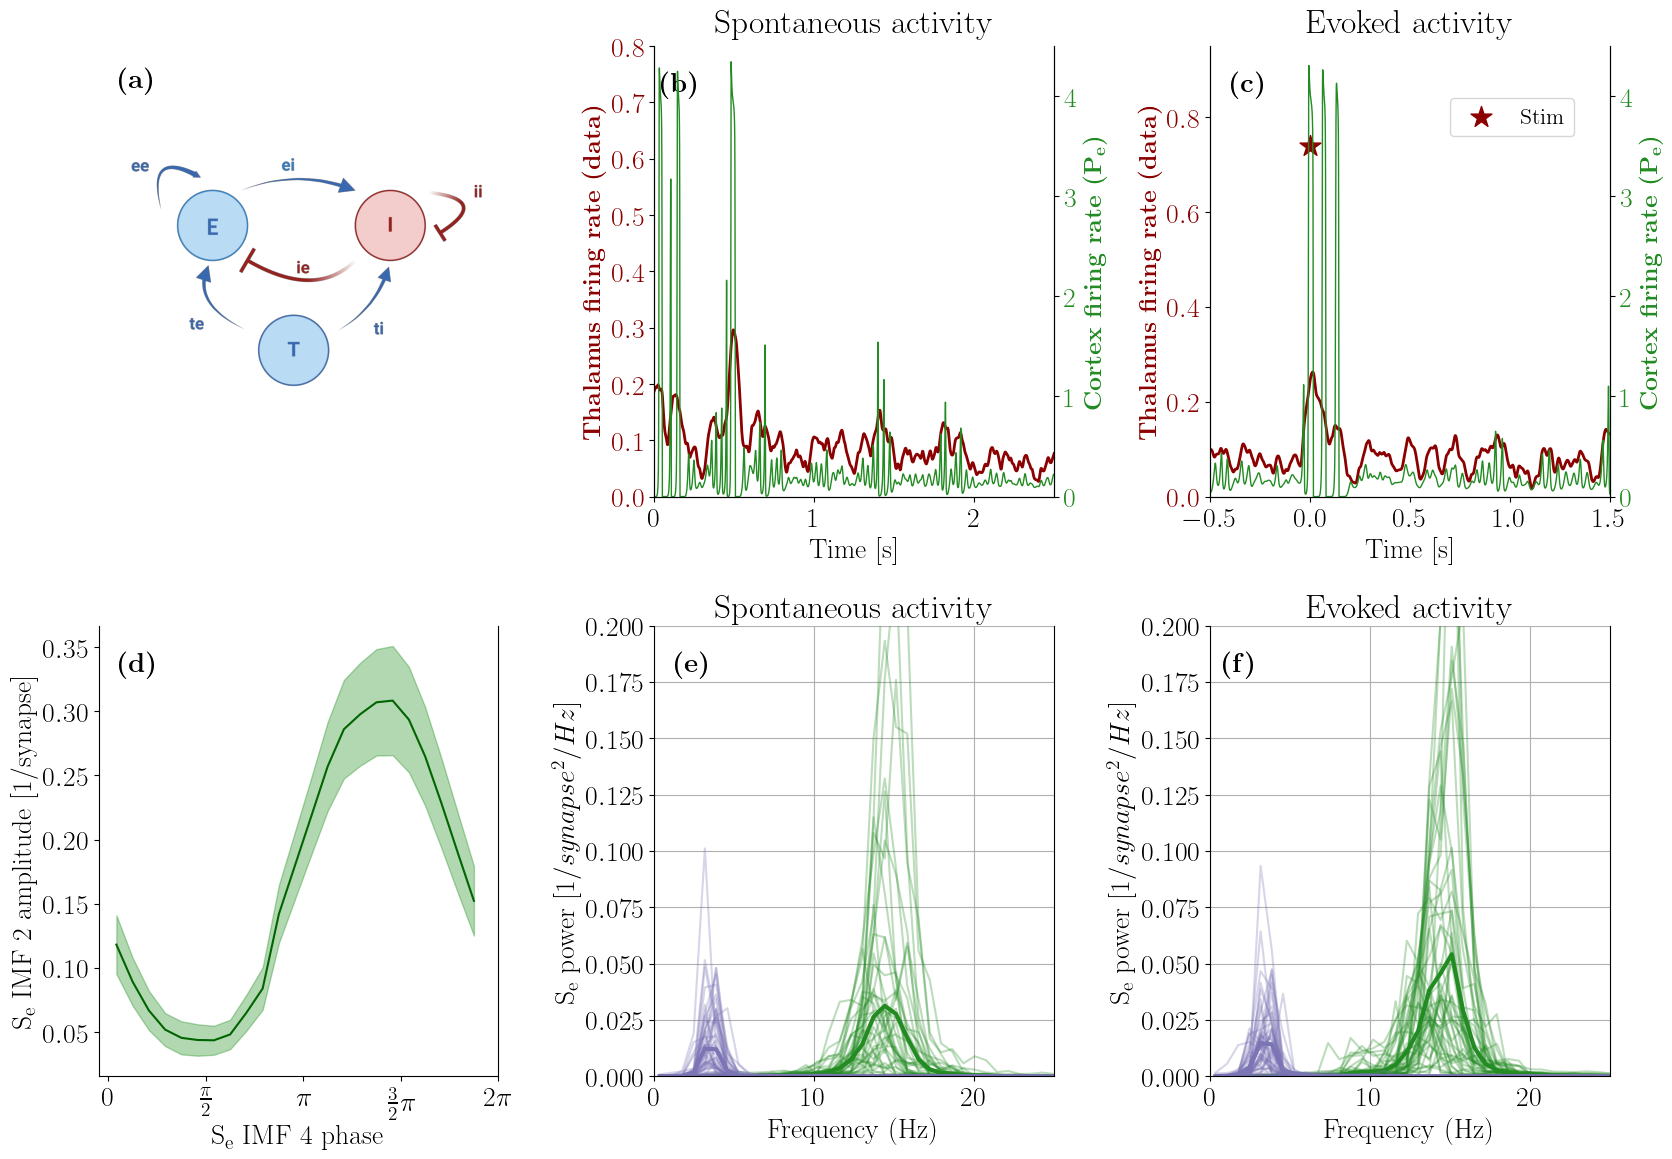

In [ ]:
import emd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import cm
import warnings

path2 = str(REPO_DIR / "figs")
warnings.filterwarnings('ignore')



trial = 1


fig, ax = plt.subplots(2,3,figsize =(17,12))
ax1 = ax[0,0]

ax1.spines['top'].set_visible(False)
ax1.spines['bottom'].set_visible(False)
ax1.spines['left'].set_visible(False)
ax1.spines['right'].set_visible(False)



ax1.set_xlim(0,3000)
ax1.set_ylim(2500,200)
ax1.set_xticks([])
ax1.set_yticks([])


ax1.imshow(plt.imread(os.path.join(path2,'Untitled (1).png')), origin ='upper',resample = 0.1,)
#fig =plt.figure()
# instantiate a second axes that shares the same x-axis
#color=colors[1]
T = 1000*3
times = np.arange(0,T,0.04)
times = times*1e-3
ax2 =ax[0,1]



S_rest = S_trial[trial,0, 25000*3:25000*6]
S_stim = S_trial[trial,0, :25000*3]

proc_rest = proc_trial[trial, 25000*3: 25000*6]
proc_stim = proc_trial[trial, :25000*3]

ax2.set_title('Spontaneous activity', pad = 10)
ax2.set_ylabel(r'\textbf{Thalamus firing rate (data)}',fontsize = 18,color = 'darkred')  # we already handled the x-label with ax1
ax2.plot(times,proc_rest, color='darkred',lw = 2, alpha = 1)
ax2.tick_params(axis='y', labelcolor='darkred')
ax2.set_xlabel('Time [s]');
ax1 = ax2.twinx()  
ax1.set_xlabel('')
ax1.set_ylabel(r'\textbf{Cortex firing rate (\textbf{P\textsubscript{e}})}',fontsize = 18, color='forestgreen')
ax1.plot(times, S_rest, color='forestgreen', lw = 1)
ax1.tick_params(axis='y', labelcolor='forestgreen')
plt.xlim(0,2.5)


ax2.set_ylim(0.,.8)
ax1.set_ylim(0.,4.5)

ax2 = ax[0,2]
ax2.set_title('Evoked activity', pad = 10)
T = 1000*3
times = np.arange(0,T,0.04)
times = times*1e-3-1
ax2.set_ylabel(r'\textbf{Thalamus firing rate (data)}',fontsize = 18,color = 'darkred')  # we already handled the x-label with ax1
ax2.plot(times,proc_stim, color='darkred',lw = 2, alpha = 1)
ax2.tick_params(axis='y', labelcolor='darkred')

ax2.set_xlabel('Time [s]');
ax1 = ax2.twinx()  
ax1.set_xlabel('')
ax1.set_ylabel(r'\textbf{Cortex firing rate (\textbf{P\textsubscript{e}})}',fontsize = 18, color='forestgreen')
ax1.plot(times, S_stim, color='forestgreen', lw = 1)
ax1.tick_params(axis='y', labelcolor='forestgreen')

ax1.scatter(0,3.5,color = 'darkred',marker ='*',s = 250, label ='Stim')
plt.legend(loc = (0.6,0.8), fontsize = 16)
plt.xlim(-.5,1.5)
ax2.set_ylim(0.,.95)
ax1.set_ylim(0.,4.5)


from scipy import ndimage
aasmean = np.roll(np.mean(np.asarray(aa1),0),10)
aas2 = np.roll(aa1,10)
ax[1,0].fill_between(phase_bins2,aasmean - np.std(aas2,0)/np.sqrt(len(aas2)),aasmean+ np.std(aas2,0)/np.sqrt(len(aas)),color='green', alpha =.3)
ax[1,0].plot(phase_bins2, aasmean, color ='darkgreen')
ax[1,0].set_xlabel(r'S\textsubscript{e} IMF 4 phase')
ax[1,0].set_ylabel(r'S\textsubscript{e} IMF 2 amplitude [1/synapse]');
ax[1,0].set_xticks([0,np.pi/2,np.pi,3/2*np.pi, 2*np.pi])
ax[1,0].set_xticklabels(["0",r"$\frac{\pi}{2}$",r"$\pi$",r"$\frac{3}{2}\pi$", r"$2\pi$"])


ax22 = ax[1,2]
ax22.plot(hht_f,final[:,:,1].T, color = 'forestgreen', alpha = 0.3);
ax22.plot(hht_f,np.mean(final[:,:,1],0), color = 'forestgreen', lw = 3);

ax22.plot(hht_f,final[:,:,3].T, color = cm.get_cmap('Purples')(0.65), alpha = 0.3)
ax22.plot(hht_f,np.mean(final[:,:,3],0), color = cm.get_cmap('Purples')(0.65), lw = 3);


#ax22.plot(hht_f,final[:,:,2].T, color = 'blue', alpha = 0.3);
#ax22.plot(hht_f,np.mean(final[:,:,2],0), color = 'blue', lw=3);

ax02 = ax[1,1]
ax02.plot(hht_f,final_rest[:,:,1].T, color = 'forestgreen', alpha = 0.3);
ax02.plot(hht_f,np.mean(final_rest[:,:,1],0), color = 'forestgreen', lw=3);

#ax02.plot(hht_f,final_rest[:,:,2].T, color = 'blue', alpha = 0.3);
#ax02.plot(hht_f,np.mean(final_rest[:,:,2],0), color = 'blue', lw=3);


ax02.plot(hht_f,final_rest[:,:,3].T, color = cm.get_cmap('Purples')(0.65), alpha = 0.3);
ax02.plot(hht_f,np.mean(final_rest[:,:,3],0), color = cm.get_cmap('Purples')(0.65), lw = 3);


ax02.grid(True)
ax22.grid(True)
ax02.set_title('Spontaneous activity')
ax22.set_title('Evoked activity')

ax02.set_xlim(0, 25)
ax22.set_xlim(0, 25)
ax02.set_ylim(0, 0.20)
ax22.set_ylim(0, 0.20)

ax02.set_xlabel('Frequency (Hz)');
ax22.set_xlabel('Frequency (Hz)');
ax02.set_ylabel(r"S\textsubscript{e} power $[1/synapse^2/Hz]$")
ax22.set_ylabel(r"S\textsubscript{e} power $[1/synapse^2/Hz]$")



ax[0,0].annotate('\\textbf{(a)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05, 1.1), textcoords='axes fraction')
ax[0,1].annotate('\\textbf{(b)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.015,0.9), textcoords='axes fraction')
ax[0,2].annotate('\\textbf{(c)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05,0.9), textcoords='axes fraction')
ax[1,0].annotate('\\textbf{(d)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05, 0.9), textcoords='axes fraction')
ax[1,1].annotate('\\textbf{(e)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.05,0.9), textcoords='axes fraction')
ax[1,2].annotate('\\textbf{(f)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.03,0.9), textcoords='axes fraction')

plt.tight_layout()
plt.savefig(path_figures+f"/Figura_5b_model_{rat}_{label}.jpg", dpi = 300, bbox_inches = 'tight')
plt.savefig(path_figures+f"/Figura_5b_model_{rat}_{label}.tif", dpi = 300, bbox_inches = 'tight')

In [ ]:
len(fs), len(fs_2);


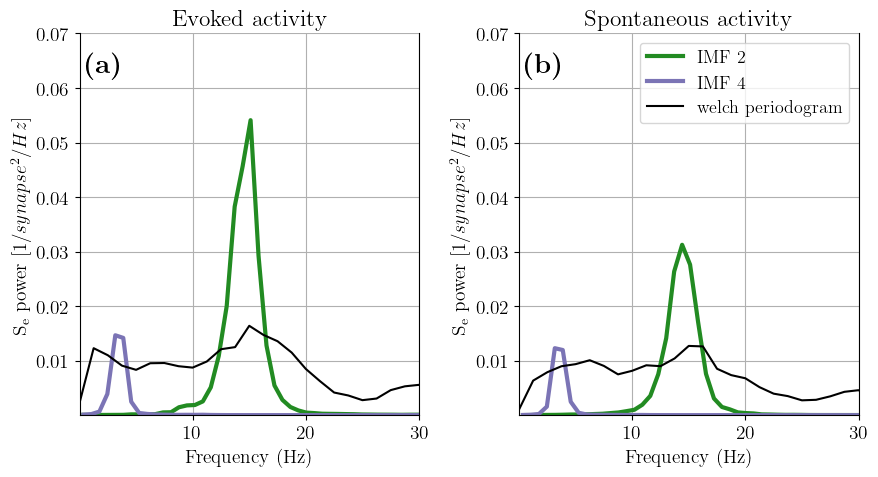

In [ ]:
import emd
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib import cm
import warnings
plt.rcParams['font.size'] =14
path2 = str(REPO_DIR / "figs")
warnings.filterwarnings('ignore')



trial = 1


fig, ax = plt.subplots(1,2,figsize =(9,5))



ax22 = ax[0]
#ax22.plot(hht_f,final[:,:,1].T, color = 'forestgreen', alpha = 0.3);
ax22.plot(hht_f,np.mean(final[:,:,1],0), color = 'forestgreen', lw = 3);

#ax22.plot(hht_f,final[:,:,3].T, color = cm.get_cmap('Purples')(0.65), alpha = 0.3)
ax22.plot(hht_f,np.mean(final[:,:,3],0), color = cm.get_cmap('Purples')(0.65), lw = 3);


#ax22.plot(fs_2,np.asarray(pspectrum_s).T, color = 'gray', alpha = 0.3);
ax22.plot(fss_2,np.mean(np.asarray(pspectrum_s),0), color = 'black', alpha = 1);

ax02 = ax[1]
#ax02.plot(hht_f,final_rest[:,:,1].T, color = 'forestgreen', alpha = 0.3);
ax02.plot(hht_f,np.mean(final_rest[:,:,1],0), color = 'forestgreen', lw=3, label ='IMF 2');
ax02.plot(hht_f,np.mean(final_rest[:,:,3],0), color = cm.get_cmap('Purples')(0.65), lw = 3,  label ='IMF 4');

#ax02.plot(fs,np.asarray(pspectrum).T, color = 'gray', alpha = 0.3);
ax02.plot(fss,np.mean(np.asarray(pspectrum),0), color = 'black', alpha = 1, label ='welch periodogram');

#ax02.plot(hht_f,np.mean(final_rest[:,:,1],0), color = 'forestgreen', lw=3);

#ax02.plot(hht_f,final_rest[:,:,3].T, color = cm.get_cmap('Purples')(0.65), alpha = 0.3);
ax02.legend(fontsize = 13)

ax02.grid(True)
ax22.grid(True)
ax02.set_title('Spontaneous activity')
ax22.set_title('Evoked activity')

ax02.set_xlim(10**-2., 30)
ax22.set_xlim(10**-2., 30)
#ax02.set_ylim(0, 0.20)
#ax22.set_ylim(0, 0.20)

ax02.set_ylim(10**-6.,0.07)
ax22.set_ylim(10**-6., 0.07)
ax02.set_xlabel('Frequency (Hz)');
ax22.set_xlabel('Frequency (Hz)');
ax02.set_ylabel(r"S\textsubscript{e} power $[1/synapse^2/Hz]$")
ax22.set_ylabel(r"S\textsubscript{e} power $[1/synapse^2/Hz]$")



ax[0].annotate('\\textbf{(a)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.015, 0.9), textcoords='axes fraction')
ax[1].annotate('\\textbf{(b)}', size = 20,
                 xy=(1, 1), xycoords='axes fraction',
                 xytext=(0.015,0.9), textcoords='axes fraction')
#ax[0].set_yscale('log')
#ax[1].set_yscale('log')
plt.tight_layout()
plt.savefig(path_figures+f"/revision_spectra.jpg", dpi = 300, bbox_inches = 'tight')
#plt.savefig(path_figures+f"/Figura_5b_model_{rat}_{label}.tif", dpi = 300, bbox_inches = 'tight')


In [ ]:
len(fs), len(fs_2),len(x)/10;


In [ ]:
np.asarray(pspectrum_s).shape;


In [ ]:
plt.rcParams['font.size'] =23

In [ ]:

x = S_trial[trial,1,25000*6:]
imf2 = emd.sift.mask_sift(x, mask_freqs =ii/sample_rate)
